# Stock Price Prediction
### Minor Project — Machine Learning & Deep Learning for Next-Day Stock Price Forecasting

**Objective.** Forecast the next trading day's closing price of Apple Inc. (AAPL) from its own price history and the
behaviour of the overall market (S&P 500 index), and evaluate how useful such predictions are to an investor —
both in terms of price error and in terms of predicting the **direction** of the market.

**Approach.**
1. Load ~9 years of daily stock data (2007 – 2016) and explore it.
2. Engineer technical-indicator features (returns, moving averages, volatility, momentum, RSI, market returns).
3. Split the data **chronologically** into train / validation / test sets (no shuffling — the future must never leak into the past).
4. Train and compare five models:
   * **Naive baseline** – tomorrow's price = today's price
   * **Drift baseline** – today's price grown by the average historical daily return
   * **Linear Regression (Ridge)**
   * **Random Forest Regressor**
   * **LSTM** recurrent neural network (TensorFlow / Keras)
5. Evaluate with RMSE, MAE, MAPE, R², and **directional accuracy**, then test a simple trading strategy built on the predictions.

> **Design decision:** every model predicts the **next-day return** (percentage change) rather than the raw price.
> The predicted price is then rebuilt as `today's close × (1 + predicted return)`. Returns are close to stationary, so
> models trained on 2007–2013 still make sense on 2015–2016 prices (tree models such as Random Forest cannot
> extrapolate to price levels they have never seen), and it makes it impossible for a model to look good simply by
> copying yesterday's price.

## 1. Setup

In [1]:
# If running on Google Colab / a fresh environment, uncomment:
# !pip install pandas numpy matplotlib seaborn scikit-learn tensorflow

import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

plt.rcParams.update({"figure.figsize": (12, 5), "axes.grid": True, "grid.alpha": 0.3})
sns.set_palette("deep")
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 2. Dataset

The dataset contains **daily adjusted closing prices** from **3 Jan 2007 to 1 Mar 2016** (2,306 trading days) for
Apple (AAPL), Microsoft (MSFT), IBM, Starbucks (SBUX) and the S&P 500 index (GSPC). It is a public Yahoo Finance
extract (the same kind of data offered by the Kaggle stock-market datasets), included alongside this notebook as
`stock_prices.csv`. If the file is missing, it is downloaded automatically.

**Using a Kaggle dataset instead:** download any daily-price CSV from Kaggle (e.g. *"Huge Stock Market Dataset"* or
*"S&P 500 stock data"*), then set `CSV_PATH`, `DATE_COL`, and `TARGET_COL` below. The rest of the notebook is unchanged.
If the file has no market-index column, set `MARKET_COL = None`.

The period covers the **2008 financial crisis**, the post-crisis recovery and the 2015 correction, so the models are
tested across very different market conditions.

In [2]:
CSV_PATH   = "stock_prices.csv"
DATA_URL   = "https://raw.githubusercontent.com/plotly/datasets/master/stockdata.csv"
DATE_COL   = "Date"
TARGET_COL = "AAPL"     # stock to predict
MARKET_COL = "GSPC"     # market index used as an extra signal (None to disable)

if not os.path.exists(CSV_PATH):
    pd.read_csv(DATA_URL).to_csv(CSV_PATH, index=False)

raw = pd.read_csv(CSV_PATH, parse_dates=[DATE_COL]).sort_values(DATE_COL).set_index(DATE_COL)
print("Shape:", raw.shape)
print("Period:", raw.index.min().date(), "→", raw.index.max().date())
raw.head()

Shape: (2306, 5)
Period: 2007-01-03 → 2016-03-01


,MSFT,IBM,SBUX,AAPL,GSPC
Date,,,,,
2007-01-03,23.950705,80.517962,16.149666,11.086612,1416.599976
2007-01-04,23.910599,81.378851,16.167992,11.332687,1418.339966
2007-01-05,23.774242,80.642129,16.099269,11.251984,1409.709961
2007-01-08,24.006852,81.867244,16.039710,11.307550,1412.839966
2007-01-09,24.030914,82.835742,15.970989,12.246870,1412.109985


In [3]:
print("Missing values per column:\n", raw.isna().sum(), "\n")
print("Duplicate dates:", raw.index.duplicated().sum())
raw.describe().round(2)

Missing values per column:
 MSFT    0
IBM     0
SBUX    0
AAPL    0
GSPC    0
dtype: int64 

Duplicate dates: 0


,MSFT,IBM,SBUX,AAPL,GSPC
count,2306.00,2306.00,2306.00,2306.00,2306.00
mean,28.74,136.24,23.21,54.72,1460.00
std,9.47,37.38,15.52,34.65,361.67
min,12.63,61.27,3.28,10.35,676.53
25%,22.58,102.41,10.79,22.93,1198.42
50%,24.99,143.83,17.90,49.33,1402.37
75%,33.87,172.57,35.31,78.10,1770.58
max,56.15,198.95,63.10,130.67,2130.82


## 3. Exploratory Data Analysis

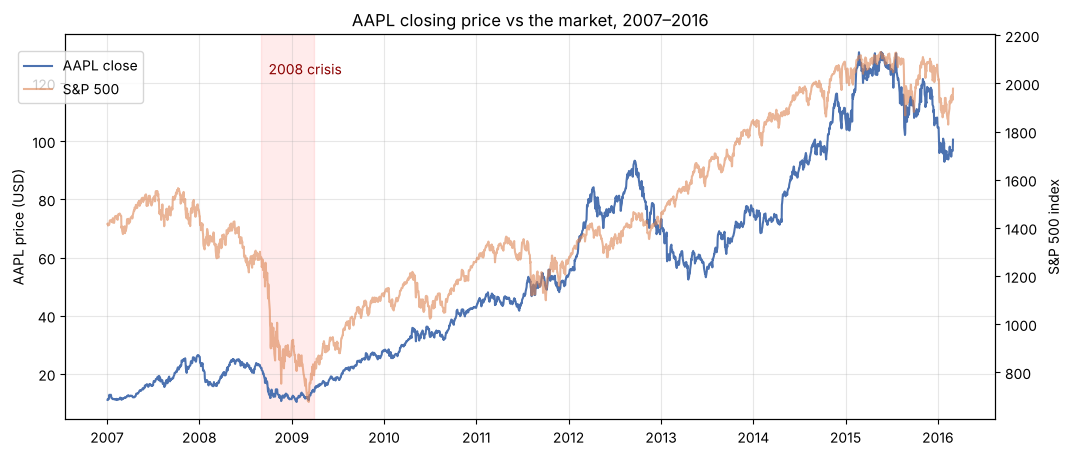

In [4]:
fig, ax1 = plt.subplots()
ax1.plot(raw.index, raw[TARGET_COL], label=f"{TARGET_COL} close", color="C0")
ax1.set_ylabel(f"{TARGET_COL} price (USD)")
if MARKET_COL:
    ax2 = ax1.twinx()
    ax2.plot(raw.index, raw[MARKET_COL], label="S&P 500", color="C1", alpha=0.6)
    ax2.set_ylabel("S&P 500 index"); ax2.grid(False)
    fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.86))
ax1.axvspan(pd.Timestamp("2008-09-01"), pd.Timestamp("2009-03-31"), color="red", alpha=0.08)
ax1.text(pd.Timestamp("2008-10-01"), ax1.get_ylim()[1]*0.9, "2008 crisis", color="darkred")
plt.title(f"{TARGET_COL} closing price vs the market, 2007–2016"); plt.show()

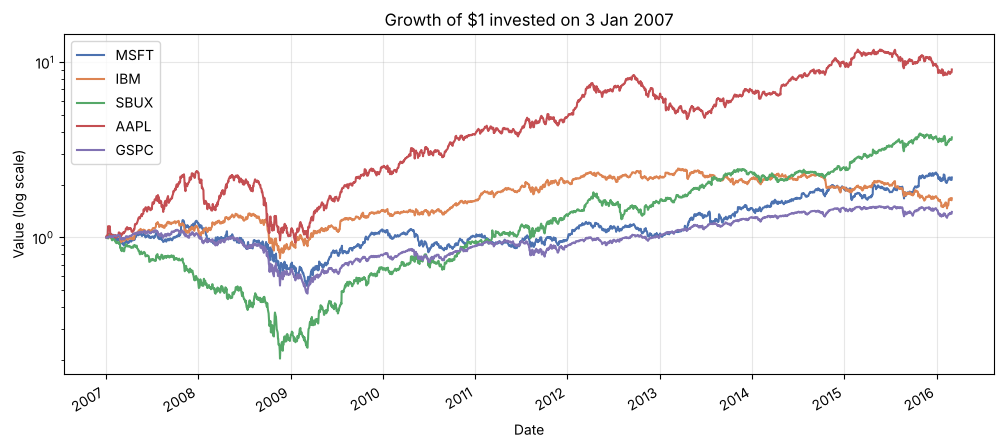

In [5]:
# Normalised growth of every stock in the file (all start at 1.0)
(raw / raw.iloc[0]).plot(title="Growth of $1 invested on 3 Jan 2007", logy=True)
plt.ylabel("Value (log scale)"); plt.show()

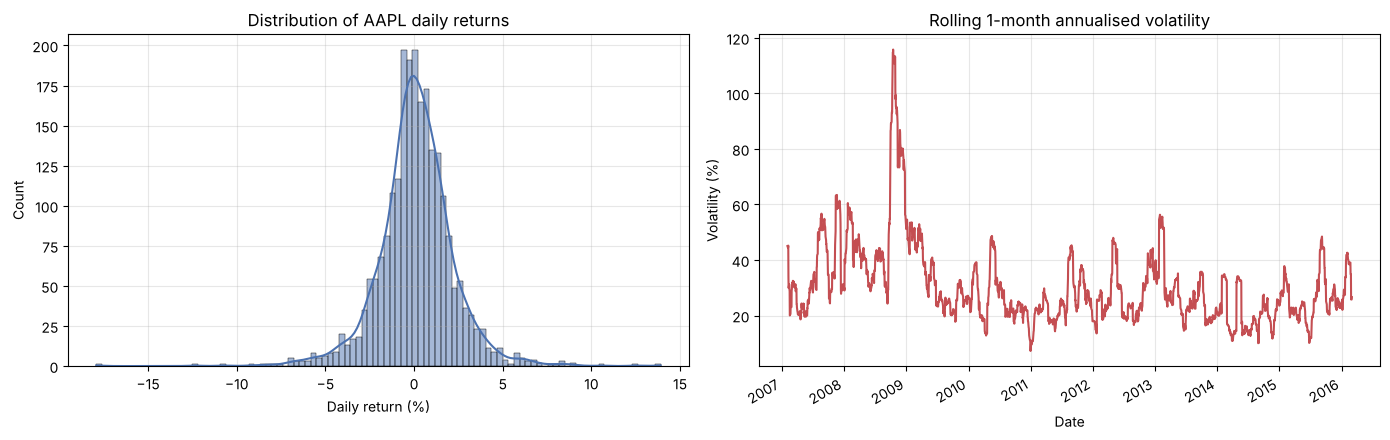

Mean daily return : 0.118%
Std of daily return: 2.131%
Skewness / kurtosis: -0.19 / 5.77  (fat tails → large surprises are common)
Share of up days   : 52.6%


In [6]:
ret = raw.pct_change().dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(ret[TARGET_COL]*100, bins=100, kde=True, ax=axes[0])
axes[0].set_title(f"Distribution of {TARGET_COL} daily returns"); axes[0].set_xlabel("Daily return (%)")
(ret[TARGET_COL].rolling(21).std()*np.sqrt(252)*100).plot(ax=axes[1], color="C3")
axes[1].set_title("Rolling 1-month annualised volatility"); axes[1].set_ylabel("Volatility (%)")
plt.tight_layout(); plt.show()

print(f"Mean daily return : {ret[TARGET_COL].mean()*100:.3f}%")
print(f"Std of daily return: {ret[TARGET_COL].std()*100:.3f}%")
print(f"Skewness / kurtosis: {ret[TARGET_COL].skew():.2f} / {ret[TARGET_COL].kurt():.2f}  (fat tails → large surprises are common)")
print(f"Share of up days   : {(ret[TARGET_COL] > 0).mean()*100:.1f}%")

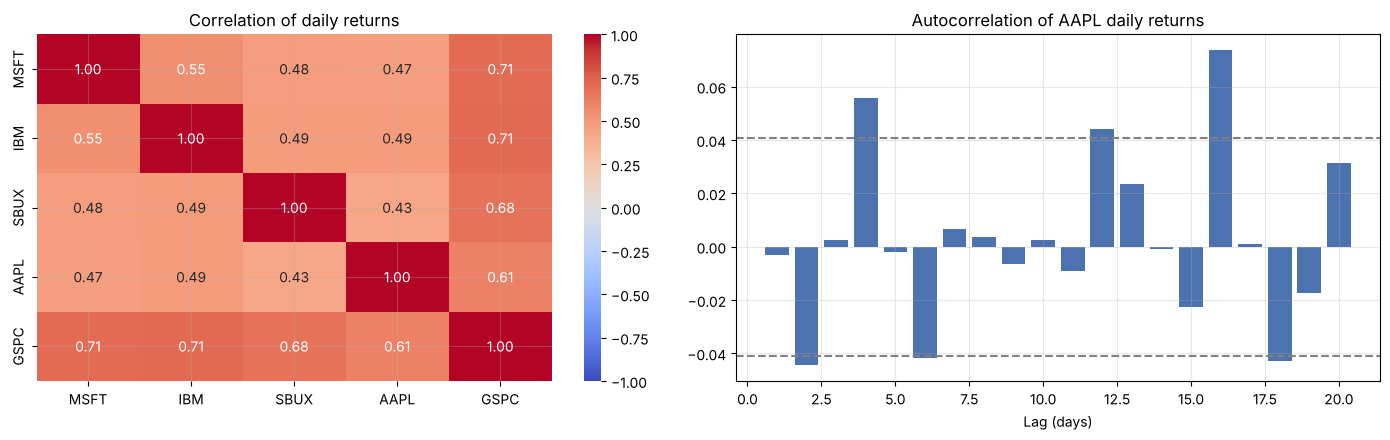

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(ret.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Correlation of daily returns")
lags = range(1, 21)
axes[1].bar(lags, [ret[TARGET_COL].autocorr(l) for l in lags])
axes[1].axhline(1.96/np.sqrt(len(ret)), ls="--", color="grey"); axes[1].axhline(-1.96/np.sqrt(len(ret)), ls="--", color="grey")
axes[1].set_title(f"Autocorrelation of {TARGET_COL} daily returns"); axes[1].set_xlabel("Lag (days)")
plt.tight_layout(); plt.show()

**EDA findings.**
* Apple grew roughly 9× over the period but fell more than 50 % during the 2008 crisis — prices are clearly **non-stationary**.
* Daily returns are centred near zero, have **fat tails** (high kurtosis) and volatility comes in **clusters**.
* Apple's returns move strongly with the S&P 500, so market behaviour is a sensible input.
* Return autocorrelations are tiny and mostly inside the significance band: yesterday's return says very little about
  today's. This is the *efficient-market* signature and sets realistic expectations — day-ahead prediction is hard.

## 4. Feature Engineering

In [8]:
def rsi(series, window=14):
    delta = series.diff()
    gain = delta.clip(lower=0).rolling(window).mean()
    loss = (-delta.clip(upper=0)).rolling(window).mean()
    return 100 - 100 / (1 + gain / loss)

px = raw[TARGET_COL]
df = pd.DataFrame(index=raw.index)
df["close"]  = px
df["ret_1"]  = px.pct_change()
for lag in range(1, 6):                                     # recent returns
    df[f"ret_lag{lag}"] = df["ret_1"].shift(lag)
for w in (5, 10, 20, 50):                                   # distance from moving averages
    df[f"ma{w}_gap"] = px / px.rolling(w).mean() - 1
df["mom_10"] = px.pct_change(10)                            # momentum
df["mom_20"] = px.pct_change(20)
df["vol_10"] = df["ret_1"].rolling(10).std()                # volatility
df["vol_20"] = df["ret_1"].rolling(20).std()
df["rsi_14"] = rsi(px) / 100
df["dow"]    = df.index.dayofweek / 4                       # day of week
if MARKET_COL:
    mret = raw[MARKET_COL].pct_change()
    df["mkt_ret_1"] = mret
    df["mkt_ret_lag1"] = mret.shift(1)
    df["mkt_ma20_gap"] = raw[MARKET_COL] / raw[MARKET_COL].rolling(20).mean() - 1
    df["rel_ret_5"] = px.pct_change(5) - raw[MARKET_COL].pct_change(5)   # performance vs market

feat_full = df.dropna().copy()          # features up to the LAST day in the file (used for the live forecast)

# TARGET: tomorrow's return. shift(-1) moves tomorrow's value onto today's row.
df["target_ret"]   = df["ret_1"].shift(-1)
df["target_close"] = px.shift(-1)

df = df.dropna()
FEATURES = [c for c in df.columns if c not in ("close", "target_ret", "target_close")]
print(f"{len(FEATURES)} features, {len(df)} usable rows")
print(FEATURES)
df[FEATURES].describe().T.round(4).head(10)

20 features, 2256 usable rows
['ret_1', 'ret_lag1', 'ret_lag2', 'ret_lag3', 'ret_lag4', 'ret_lag5', 'ma5_gap', 'ma10_gap', 'ma20_gap', 'ma50_gap', 'mom_10', 'mom_20', 'vol_10', 'vol_20', 'rsi_14', 'dow', 'mkt_ret_1', 'mkt_ret_lag1', 'mkt_ma20_gap', 'rel_ret_5']


,count,mean,std,min,25%,50%,75%,max
ret_1,2256.0,0.0012,0.0213,-0.1792,-0.0090,0.0011,0.0123,0.1390
ret_lag1,2256.0,0.0012,0.0213,-0.1792,-0.0090,0.0011,0.0123,0.1390
ret_lag2,2256.0,0.0012,0.0213,-0.1792,-0.0090,0.0011,0.0123,0.1390
ret_lag3,2256.0,0.0012,0.0213,-0.1792,-0.0090,0.0011,0.0123,0.1390
ret_lag4,2256.0,0.0012,0.0213,-0.1792,-0.0090,0.0011,0.0123,0.1390
ret_lag5,2256.0,0.0012,0.0213,-0.1792,-0.0090,0.0011,0.0123,0.1390
ma5_gap,2256.0,0.0020,0.0229,-0.1525,-0.0099,0.0028,0.0154,0.1612
ma10_gap,2256.0,0.0045,0.0354,-0.1905,-0.0153,0.0061,0.0269,0.1257
ma20_gap,2256.0,0.0096,0.0529,-0.2854,-0.0195,0.0117,0.0433,0.1541
ma50_gap,2256.0,0.0255,0.0916,-0.4078,-0.0211,0.0275,0.0813,0.2740


Every feature on row *t* is computed **only from information available at the close of day *t*** — rolling windows
look backwards and the target is shifted forward. This avoids *look-ahead bias*, the most common mistake in stock
prediction projects.

## 5. Chronological Train / Validation / Test Split

Train      : 2007-03-15 → 2013-06-20  (1579 days)
Validation : 2013-06-21 → 2014-10-22  (338 days)
Test       : 2014-10-23 → 2016-02-29  (339 days)


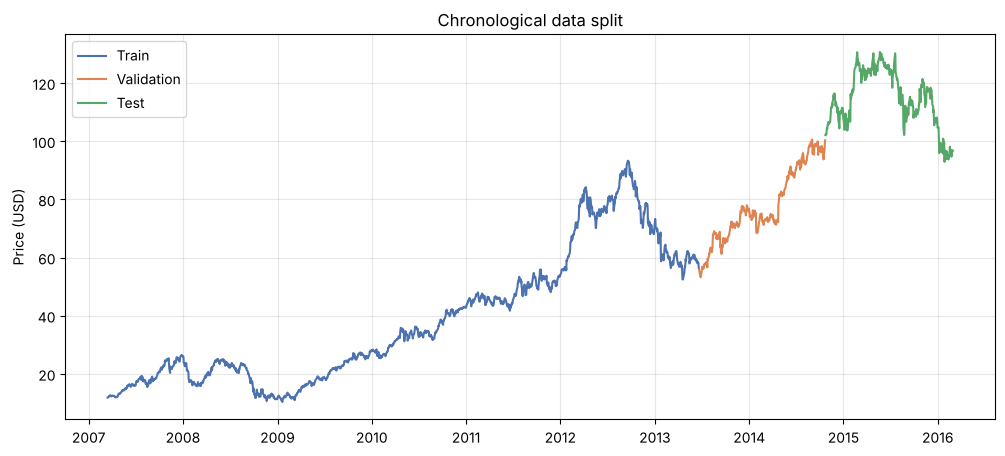

In [9]:
n = len(df)
train_end, val_end = int(n * 0.70), int(n * 0.85)
train, val, test = df.iloc[:train_end], df.iloc[train_end:val_end], df.iloc[val_end:]

for name, part in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"{name:<11}: {part.index.min().date()} → {part.index.max().date()}  ({len(part)} days)")

X_train, y_train = train[FEATURES], train["target_ret"]
X_val,   y_val   = val[FEATURES],   val["target_ret"]
X_test,  y_test  = test[FEATURES],  test["target_ret"]

plt.plot(train.index, train["close"], label="Train")
plt.plot(val.index,   val["close"],   label="Validation")
plt.plot(test.index,  test["close"],  label="Test")
plt.title("Chronological data split"); plt.ylabel("Price (USD)"); plt.legend(); plt.show()

## 6. Evaluation Metrics

In [10]:
results, predictions = {}, {}

def evaluate(name, pred_ret, part=None):
    # Score a model from its predicted next-day returns on a split.
    part = test if part is None else part
    pred_ret = np.asarray(pred_ret, dtype=float)
    pred_price = part["close"].values * (1 + pred_ret)
    actual = part["target_close"].values
    true_dir = part["target_ret"].values > 0
    metrics = {
        "RMSE ($)": np.sqrt(mean_squared_error(actual, pred_price)),
        "MAE ($)":  mean_absolute_error(actual, pred_price),
        "MAPE (%)": np.mean(np.abs((actual - pred_price) / actual)) * 100,
        "R² (price)": r2_score(actual, pred_price),
        "Directional acc. (%)": (np.mean((pred_ret > 0) == true_dir) * 100) if np.any(pred_ret != 0) else np.nan,
    }
    if part is test:
        results[name] = metrics
        predictions[name] = pd.Series(pred_price, index=part.index)
    return metrics

def show(metrics):
    return pd.Series(metrics).round(3).to_frame("value").T

* **RMSE / MAE** – average size of the price error in dollars (RMSE punishes large misses more).
* **MAPE** – average error as a percentage of the price.
* **R²** – share of the price variation explained.
* **Directional accuracy** – how often the model gets *up vs down* right. For a trader this matters more than the
  dollar error; **50 % is a coin flip**.

## 7. Baseline Models

In [11]:
# Naive (random walk): tomorrow = today  → predicted return 0
show(evaluate("Naive (tomorrow = today)", np.zeros(len(test))))

,RMSE ($),MAE ($),MAPE (%),R² (price),Directional acc. (%)
value,1.903,1.446,1.281,0.962,NaN


In [12]:
# Drift: grow today's price by the average daily return seen in training
drift = y_train.mean()
print(f"Average training daily return: {drift*100:.3f}%")
show(evaluate("Drift (avg. return)", np.full(len(test), drift)))

Average training daily return: 0.125%


,RMSE ($),MAE ($),MAPE (%),R² (price),Directional acc. (%)
value,1.91,1.454,1.288,0.961,48.673


The naive baseline is **very hard to beat** on price error: stock prices move only ~1–2 % a day, so "same as today"
is already close. Any model worth using must beat it — R² on price looks impressive for every model here simply
because prices are highly autocorrelated, which is why we never judge a model by price R² alone.

## 8. Model 1 — Linear Regression (Ridge)

In [13]:
best_alpha, best_rmse = None, np.inf
for alpha in [0.1, 1, 10, 100, 1_000, 10_000, 100_000]:
    m = make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(X_train, y_train)
    r = np.sqrt(mean_squared_error(y_val, m.predict(X_val)))
    print(f"alpha={alpha:<6} validation RMSE (return) = {r:.5f}")
    if r < best_rmse: best_alpha, best_rmse = alpha, r

lin = make_pipeline(StandardScaler(), Ridge(alpha=best_alpha))
lin.fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))      # refit on train+val
lin_pred = lin.predict(X_test)
print(f"\nChosen alpha = {best_alpha}  (the largest value tried)")
print(f"Spread of predicted returns: {lin_pred.std()*100:.4f}%  vs actual daily std {y_test.std()*100:.2f}%")
show(evaluate("Linear Regression (Ridge)", lin_pred))

alpha=0.1    validation RMSE (return) = 0.01461
alpha=1      validation RMSE (return) = 0.01460
alpha=10     validation RMSE (return) = 0.01460
alpha=100    validation RMSE (return) = 0.01457
alpha=1000   validation RMSE (return) = 0.01448
alpha=10000  validation RMSE (return) = 0.01441
alpha=100000 validation RMSE (return) = 0.01439

Chosen alpha = 100000  (the largest value tried)
Spread of predicted returns: 0.0041%  vs actual daily std 1.71%


,RMSE ($),MAE ($),MAPE (%),R² (price),Directional acc. (%)
value,1.911,1.455,1.289,0.961,48.673


**Interpretation.** Validation error kept falling as the penalty grew, so tuning picked the strongest regularisation —
which shrinks every coefficient almost to zero. The model ends up predicting (nearly) the average return every day,
i.e. it behaves like the *Drift* baseline. This is a meaningful result: **a linear combination of these technical
indicators does not generalise to unseen years** better than "assume the average".

## 9. Model 2 — Random Forest Regressor

In [14]:
best_params, best_rmse = None, np.inf
for depth in [3, 5, 8]:
    for leaf in [20, 50]:
        m = RandomForestRegressor(n_estimators=300, max_depth=depth, min_samples_leaf=leaf,
                                  max_features=0.5, n_jobs=-1, random_state=SEED).fit(X_train, y_train)
        r = np.sqrt(mean_squared_error(y_val, m.predict(X_val)))
        print(f"max_depth={depth}, min_samples_leaf={leaf:<3} validation RMSE = {r:.5f}")
        if r < best_rmse: best_params, best_rmse = (depth, leaf), r

rf = RandomForestRegressor(n_estimators=300, max_depth=best_params[0], min_samples_leaf=best_params[1],
                           max_features=0.5, n_jobs=-1, random_state=SEED)
rf.fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))
rf_pred = rf.predict(X_test)
print(f"\nChosen max_depth={best_params[0]}, min_samples_leaf={best_params[1]}")
show(evaluate("Random Forest", rf_pred))

max_depth=3, min_samples_leaf=20  validation RMSE = 0.01442


max_depth=3, min_samples_leaf=50  validation RMSE = 0.01442


max_depth=5, min_samples_leaf=20  validation RMSE = 0.01444


max_depth=5, min_samples_leaf=50  validation RMSE = 0.01443


max_depth=8, min_samples_leaf=20  validation RMSE = 0.01448


max_depth=8, min_samples_leaf=50  validation RMSE = 0.01439



Chosen max_depth=8, min_samples_leaf=50


,RMSE ($),MAE ($),MAPE (%),R² (price),Directional acc. (%)
value,1.911,1.444,1.281,0.961,53.392


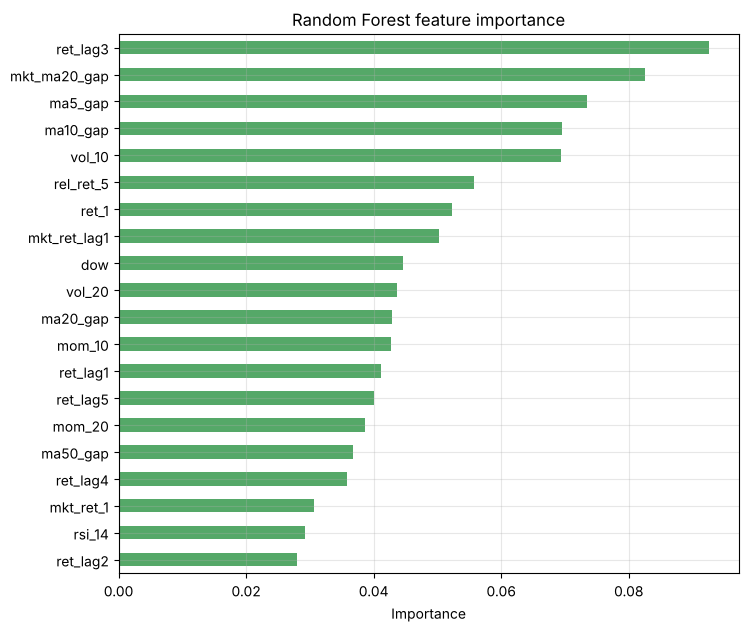

In [15]:
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
imp.plot.barh(figsize=(8, 7), color="C2", title="Random Forest feature importance")
plt.xlabel("Importance"); plt.show()

## 10. Model 3 — LSTM (Long Short-Term Memory) Neural Network

An LSTM reads a **sequence** of the last `LOOKBACK` days of features and learns temporal patterns that the tabular
models cannot see directly. Inputs and target are standardised using statistics from the **training set only**.
Early stopping on the validation set prevents over-fitting.

In [16]:
LOOKBACK = 30

x_scaler = StandardScaler().fit(X_train)
y_mean, y_std = y_train.mean(), y_train.std()

X_all = x_scaler.transform(df[FEATURES])
y_all = ((df["target_ret"] - y_mean) / y_std).values

def make_sequences(start, end):
    # Window ending on day i (inclusive) predicts day i's target; uses earlier days as context.
    xs, ys = [], []
    for i in range(max(start, LOOKBACK - 1), end):
        xs.append(X_all[i - LOOKBACK + 1: i + 1]); ys.append(y_all[i])
    return np.array(xs), np.array(ys)

Xs_train, ys_train = make_sequences(0, train_end)
Xs_val,   ys_val   = make_sequences(train_end, val_end)
Xs_test,  ys_test  = make_sequences(val_end, n)
print("Sequence shapes:", Xs_train.shape, Xs_val.shape, Xs_test.shape)

Sequence shapes: (1550, 30, 20) (338, 30, 20) (339, 30, 20)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 32)         │         6,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 16)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,065 (39.32 KB)

 Trainable params: 10,065 (39.32 KB)

 Non-trainable params: 0 (0.00 B)

Trained for 19 epochs (best epoch: 9)


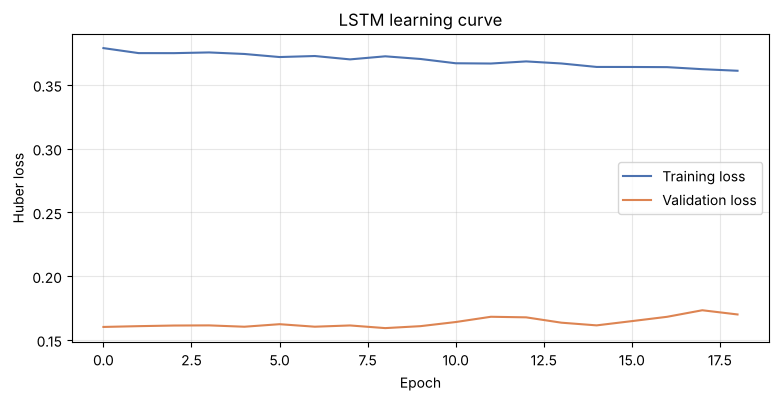

In [17]:
def build_lstm():
    model = keras.Sequential([
        layers.Input(shape=(LOOKBACK, len(FEATURES))),
        layers.LSTM(32, return_sequences=True),
        layers.Dropout(0.3),
        layers.LSTM(16),
        layers.Dropout(0.3),
        layers.Dense(8, activation="relu"),
        layers.Dense(1),
    ])
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="huber")   # Huber loss is robust to fat-tailed returns
    return model

lstm = build_lstm()
lstm.summary()

early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
history = lstm.fit(Xs_train, ys_train, validation_data=(Xs_val, ys_val),
                   epochs=100, batch_size=32, shuffle=True, callbacks=[early], verbose=0)
print(f"Trained for {len(history.history['loss'])} epochs (best epoch: {np.argmin(history.history['val_loss'])+1})")

plt.figure(figsize=(9, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("LSTM learning curve"); plt.xlabel("Epoch"); plt.ylabel("Huber loss"); plt.legend(); plt.show()

In [18]:
lstm_pred = lstm.predict(Xs_test, verbose=0).ravel() * y_std + y_mean
show(evaluate("LSTM", lstm_pred))

,RMSE ($),MAE ($),MAPE (%),R² (price),Directional acc. (%)
value,1.923,1.459,1.294,0.961,49.263


## 11. Results & Model Comparison

In [19]:
res = pd.DataFrame(results).T
res["Beats naive on RMSE?"] = np.where(res["RMSE ($)"] < res.loc["Naive (tomorrow = today)", "RMSE ($)"], "yes", "no")
always_up = (y_test > 0).mean() * 100
print(f"Test period: {test.index.min().date()} → {test.index.max().date()}  |  "
      f"'always predict UP' directional accuracy = {always_up:.1f}%\n")
res.round(3)

Test period: 2014-10-23 → 2016-02-29  |  'always predict UP' directional accuracy = 48.7%



,RMSE ($),MAE ($),MAPE (%),R² (price),Directional acc. (%),Beats naive on RMSE?
Naive (tomorrow = today),1.903,1.446,1.281,0.962,NaN,no
Drift (avg. return),1.910,1.454,1.288,0.961,48.673,no
Linear Regression (Ridge),1.911,1.455,1.289,0.961,48.673,no
Random Forest,1.911,1.444,1.281,0.961,53.392,no
LSTM,1.923,1.459,1.294,0.961,49.263,no


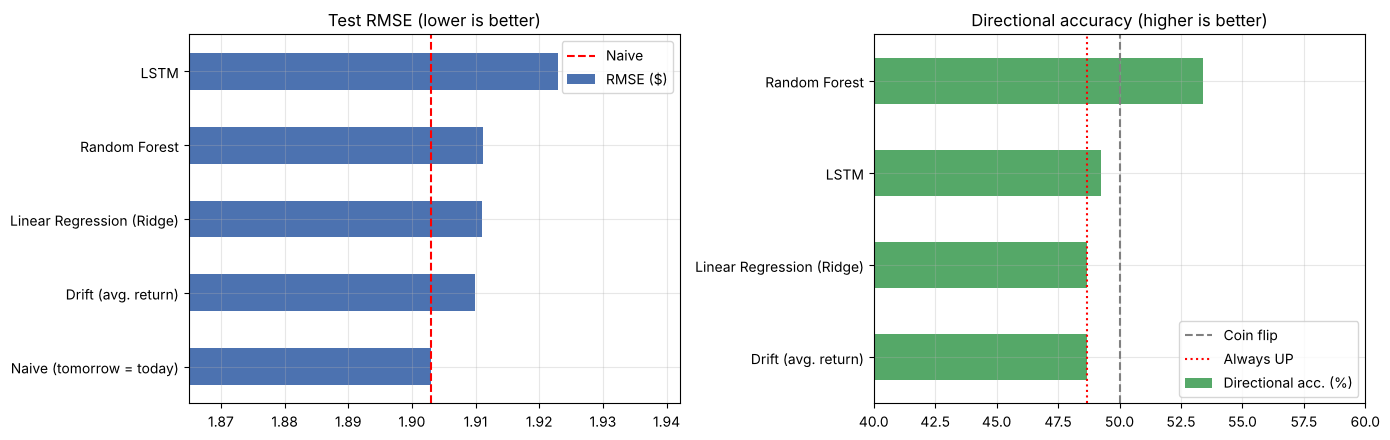

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
res["RMSE ($)"].sort_values().plot.barh(ax=axes[0], color="C0", title="Test RMSE (lower is better)")
axes[0].axvline(res.loc["Naive (tomorrow = today)", "RMSE ($)"], ls="--", color="red", label="Naive")
axes[0].set_xlim(res["RMSE ($)"].min()*0.98, res["RMSE ($)"].max()*1.01); axes[0].legend()
res["Directional acc. (%)"].dropna().sort_values().plot.barh(ax=axes[1], color="C2", title="Directional accuracy (higher is better)")
axes[1].axvline(50, ls="--", color="grey", label="Coin flip")
axes[1].axvline(always_up, ls=":", color="red", label="Always UP")
axes[1].set_xlim(40, max(60, res["Directional acc. (%)"].max()+2)); axes[1].legend()
plt.tight_layout(); plt.show()

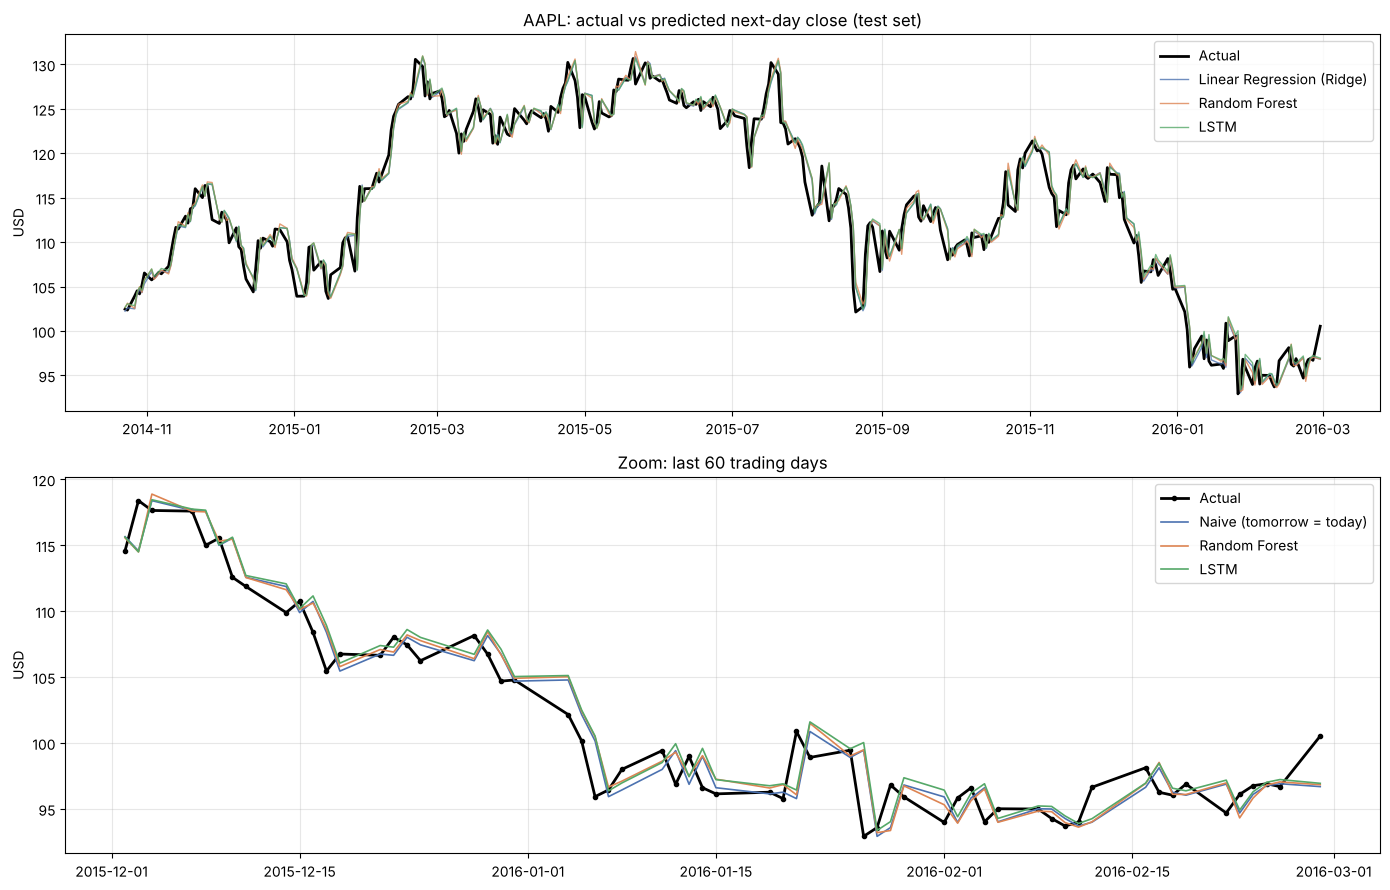

In [21]:
actual = test["target_close"]
fig, axes = plt.subplots(2, 1, figsize=(14, 9))
axes[0].plot(actual.index, actual, color="black", lw=2, label="Actual")
for name in ["Linear Regression (Ridge)", "Random Forest", "LSTM"]:
    axes[0].plot(predictions[name].index, predictions[name], lw=1, alpha=0.8, label=name)
axes[0].set_title(f"{TARGET_COL}: actual vs predicted next-day close (test set)"); axes[0].set_ylabel("USD"); axes[0].legend()

last = actual.index[-60:]
axes[1].plot(last, actual.loc[last], "k-o", ms=3, lw=2, label="Actual")
for name in ["Naive (tomorrow = today)", "Random Forest", "LSTM"]:
    axes[1].plot(last, predictions[name].loc[last], "-", lw=1.2, label=name)
axes[1].set_title("Zoom: last 60 trading days"); axes[1].set_ylabel("USD"); axes[1].legend()
plt.tight_layout(); plt.show()

**Why do the prediction lines look like the actual line shifted one day to the right?** Because each prediction is
*today's price plus a tiny predicted change*. When the models cannot find a strong signal, the best guess for
tomorrow is close to today — so the forecast "follows" the price with a one-day lag. Many stock-prediction tutorials
show this picture and present it as success; the comparison against the naive baseline shows it is not.

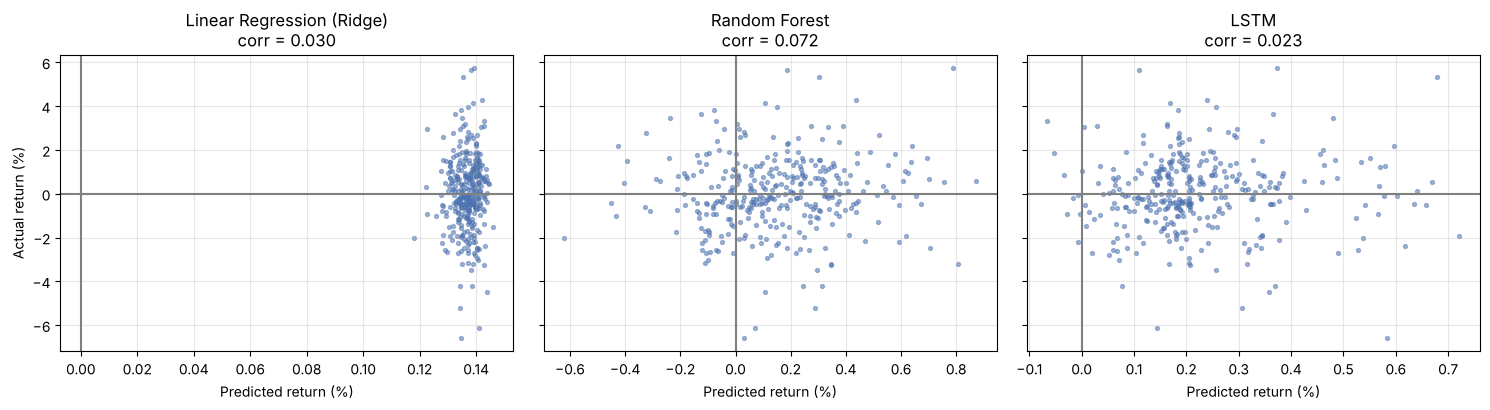

In [22]:
# How well do predicted returns line up with what actually happened?
pred_rets = {"Linear Regression (Ridge)": lin_pred, "Random Forest": rf_pred, "LSTM": lstm_pred}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, (name, p) in zip(axes, pred_rets.items()):
    ax.scatter(p*100, y_test*100, s=8, alpha=0.5)
    ax.axhline(0, color="grey"); ax.axvline(0, color="grey")
    corr = np.corrcoef(p, y_test)[0, 1]
    ax.set_title(f"{name}\ncorr = {corr:.3f}"); ax.set_xlabel("Predicted return (%)")
axes[0].set_ylabel("Actual return (%)")
plt.tight_layout(); plt.show()

### Is the directional accuracy better than chance?

In [23]:
from scipy.stats import binomtest
rows = []
for name, p in pred_rets.items():
    hits = int(np.sum((p > 0) == (y_test.values > 0)))
    test_res = binomtest(hits, len(y_test), 0.5, alternative="greater")
    lo, hi = binomtest(hits, len(y_test), 0.5).proportion_ci(confidence_level=0.95)
    rows.append({"Model": name, "Correct days": f"{hits}/{len(y_test)}", "Accuracy (%)": hits/len(y_test)*100,
                 "95% CI (%)": f"{lo*100:.1f} – {hi*100:.1f}", "p-value vs 50%": test_res.pvalue})
pd.DataFrame(rows).set_index("Model").round(3)

,Correct days,Accuracy (%),95% CI (%),p-value vs 50%
Model,,,,
Linear Regression (Ridge),165/339,48.673,43.2 – 54.1,0.706
Random Forest,181/339,53.392,47.9 – 58.8,0.116
LSTM,167/339,49.263,43.8 – 54.7,0.628


A one-sided binomial test asks: *if the model were just flipping a coin, how likely is a score this high?*
A p-value above 0.05 means the result **could easily be luck**. With only ~340 test days, a model needs roughly
55 % accuracy before we can be confident it is better than chance.

## 12. Does it make money? A simple trading simulation

Strategy: at each close, **buy (hold) the stock for the next day if the model predicts a positive return, otherwise
stay in cash**. Compared against simply buying and holding. Transaction costs, slippage and taxes are ignored, so
this is an optimistic upper bound.

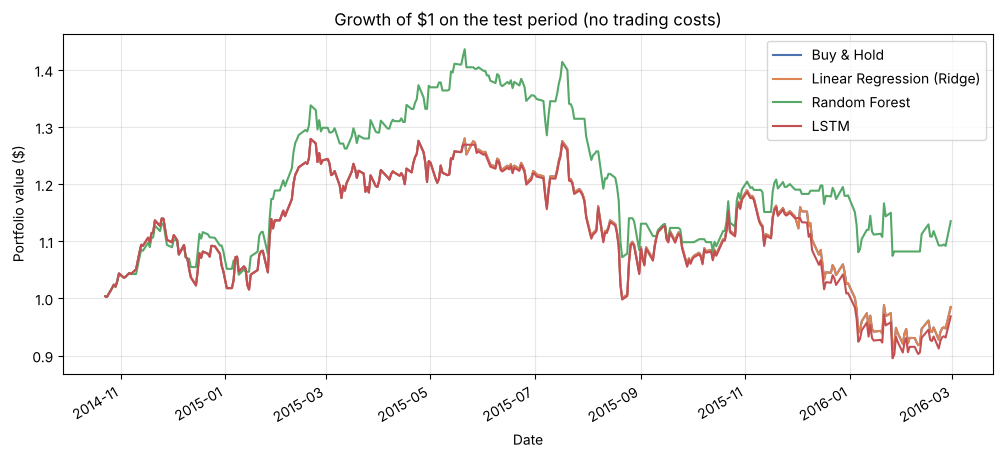

,Total return (%),Days invested (%),Max drawdown (%)
Buy & Hold,-1.51,100.00,-28.89
Linear Regression (Ridge),-1.51,100.00,-28.89
Random Forest,13.53,73.45,-25.36
LSTM,-3.15,97.64,-30.03


In [24]:
equity = pd.DataFrame(index=test.index)
equity["Buy & Hold"] = (1 + y_test).cumprod()
for name, p in pred_rets.items():
    equity[name] = (1 + y_test * (p > 0)).cumprod()

equity.plot(title="Growth of $1 on the test period (no trading costs)")
plt.ylabel("Portfolio value ($)"); plt.show()

summary = pd.DataFrame({
    "Total return (%)": (equity.iloc[-1] - 1) * 100,
    "Days invested (%)": [100] + [(p > 0).mean()*100 for p in pred_rets.values()],
    "Max drawdown (%)": ((equity / equity.cummax()) - 1).min() * 100,
})
summary.round(2)

Because the directional accuracy is not statistically significant, **any out-performance here should be treated as
luck, not evidence of a working strategy**. A strategy that trades on a ~50 % signal will, on average, lose money once
transaction costs are included.

## 13. Forecasting the Next Trading Day

In [25]:
last_row   = feat_full.iloc[[-1]]
last_date  = last_row.index[0]
last_close = raw.loc[last_date, TARGET_COL]

f_lin  = lin.predict(last_row[FEATURES])[0]
f_rf   = rf.predict(last_row[FEATURES])[0]
window = x_scaler.transform(feat_full[FEATURES].iloc[-LOOKBACK:])
f_lstm = lstm.predict(window[None, ...], verbose=0).ravel()[0] * y_std + y_mean

print(f"Last date in the data: {last_date.date()}   close = ${last_close:.2f}\n")
print("Forecast for the next trading day:")
for name, r in [("Linear Regression", f_lin), ("Random Forest", f_rf), ("LSTM", f_lstm)]:
    print(f"  {name:<18} → ${last_close*(1+r):.2f}  ({r*100:+.2f}%, {'UP' if r > 0 else 'DOWN'})")

Last date in the data: 2016-03-01   close = $100.53

Forecast for the next trading day:
  Linear Regression  → $100.67  (+0.14%, UP)
  Random Forest      → $101.17  (+0.64%, UP)
  LSTM               → $100.77  (+0.24%, UP)


To forecast from fresh data, append the newest rows to the CSV and re-run the notebook — the last cell always
predicts the day after the final date in the file.

## 14. Conclusion

**What was built.** A full, leak-free forecasting pipeline: data loading and cleaning, exploratory analysis,
20 technical/market features, chronological validation, hyper-parameter tuning on a validation set, three predictive
models (Ridge regression, Random Forest, LSTM), two baselines, error and direction metrics, and a trading simulation.

**Key findings** (test period 23 Oct 2014 – 29 Feb 2016, 339 trading days):
1. Every model tracks the price curve closely (price R² ≈ 0.96, MAPE ≈ 1.3 %), but **so does the naive
   "tomorrow = today" baseline — and none of the models beat it on RMSE** (naive $1.90 vs $1.91–1.92 for the models).
2. **Random Forest** had the best directional accuracy (**53.4 %**, 181 of 339 days) and the lowest MAE among the
   trained models, ahead of the LSTM (≈ 49 %) and Ridge (48.7 %). However, the binomial test (p ≈ 0.12) shows **none of
   these is statistically better than a coin flip** at the 5 % level.
3. The **LSTM was not better** than the simpler models. With ~1,550 noisy training sequences it stopped early and
   learned little beyond the average return; a shallow Random Forest is competitive, faster and easier to explain.
4. Validation-based tuning drove **Ridge regression to maximum regularisation**, collapsing it into the "average
   return" drift baseline — the features carry essentially no *linear* information about tomorrow's return.
5. The Random Forest trading rule happened to finish +13.5 % against −1.5 % for buy-and-hold, but given point 2 this
   should be treated as luck rather than a reliable edge.

These results are consistent with the **Efficient Market Hypothesis**: publicly available price history is
already reflected in the price, so it contains little reliable information about tomorrow's move.

**Limitations.**
* Uses only price data (no fundamentals, news, sentiment, or macro-economic data).
* One stock and one historical period (2007–2016); results may differ for other stocks or market regimes.
* A single train/test split — walk-forward (rolling-origin) validation would give a more robust estimate.
* The trading simulation ignores transaction costs, which would reduce any strategy that trades often.

**Future work.**
* Add **news and social-media sentiment** (e.g. FinBERT on headlines) and fundamental data (earnings, P/E).
* Walk-forward validation and statistical tests (e.g. Diebold–Mariano) for comparing forecasts.
* Gradient boosting (XGBoost / LightGBM), GRU, Temporal Convolutional Networks or Transformer models.
* Predict over longer horizons (weekly / monthly) where signals may be stronger than day-to-day noise.
* Probabilistic forecasts (prediction intervals) rather than a single point estimate.

> ⚠️ This project is for educational purposes only and is **not financial advice**.